# Molecular Dynamics Hands-On — Google Colab

**From a crystal structure to a protein MD trajectory, with no Windows installation.** Open in Google Colab, run the cells in order, and save your results to Google Drive.

- **Integrator:** OpenMM `VerletIntegrator` (leap-frog Verlet) throughout the dynamics.
- **Temperature coupling:** an explicit **Andersen thermostat** force in NVT, NPT and production. Verlet itself does **not** control temperature.
- **Pressure coupling:** Monte Carlo barostat in NPT and production only.
- **Example:** ubiquitin (PDB `1UBQ`), AMBER14/TIP3P, a 5 ps production run.
- **Outputs:** energy/temperature, Cα RMSD to the **original crystal PDB**, heavy-atom radius of gyration with crystal baseline, PNG/CSV, production-only DCD, resumable blocks.

This is a short **teaching exercise**, not a production-quality convergence study. Google Colab runtimes are temporary; completed stages and blocks are saved in Google Drive. CPU only; no CUDA needed on student PCs.


## 1 — Install required packages inside Colab (no Conda or local setup)

In [1]:
# Run this once per new Google Colab runtime. No Miniforge, WSL, Windows setup, or CUDA required.
import sys, subprocess, importlib.util
packages = ["openmm>=8.2,<9", "pdbfixer==1.12.0", "mdtraj>=1.10,<2", "py3Dmol>=2.0,<3"]
needed = [m for m in ('openmm','pdbfixer','mdtraj','py3Dmol') if importlib.util.find_spec(m) is None]
if needed:
    print('Installing simulation libraries in the temporary Colab runtime...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--prefer-binary', '--progress-bar', 'on', *packages])
else:
    print('Simulation libraries already installed in this Colab runtime.')
import openmm, pdbfixer, mdtraj, py3Dmol, numpy, pandas, matplotlib
from openmm import Platform
print('Python:',sys.version.split()[0], '| OpenMM:',openmm.__version__, '| MDTraj:',mdtraj.__version__)
print('OpenMM platforms:',[Platform.getPlatform(i).getName() for i in range(Platform.getNumPlatforms())])
print('All libraries available.')

Installing simulation libraries in the temporary Colab runtime...
Python: 3.13.18 | OpenMM: 8.6.1 | MDTraj: 1.11.2
OpenMM platforms: ['Reference', 'CPU']
All libraries available.


## 2 — Connect Google Drive (persistent results and checkpoints)

Colab runtime disks are temporary. **Google Drive is the default storage** so that completed stages and output files remain available if the session disconnects. You will be asked to authorize access. If your institution blocks Drive mounting, disable `USE_GOOGLE_DRIVE` and download the results ZIP before disconnecting.

In [2]:
from pathlib import Path
USE_GOOGLE_DRIVE = True   # strongly recommended for saved results/checkpoints
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = Path('/content/drive/MyDrive/MD_HandsOn_Colab')
else:
    BASE_DIR = Path('/content/MD_HandsOn_Colab')
BASE_DIR.mkdir(parents=True, exist_ok=True)
print('All results will be saved in:', BASE_DIR)

Mounted at /content/drive
All results will be saved in: /content/drive/MyDrive/MD_HandsOn_Colab


## 0 · Physical basis: bonded and nonbonded interactions

An MD force field approximates potential energy using bond stretching, angle bending, torsions, and nonbonded electrostatic/van der Waals interactions. Use the plot below to see simplified terms before simulating a real protein.

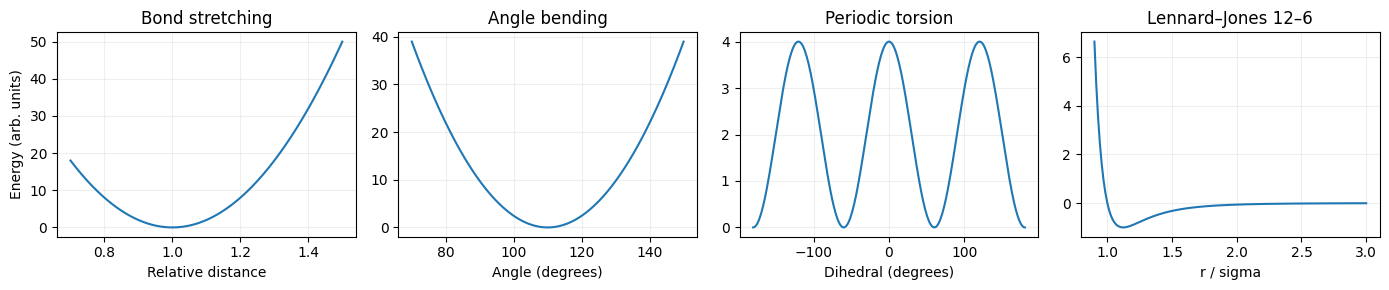

In [3]:
from pathlib import Path
import math
import matplotlib.pyplot as plt
import numpy as np
r = np.linspace(0.7, 1.5, 250)
angles = np.linspace(70, 150, 250)
theta = np.deg2rad(angles - 110)
phi = np.linspace(-180, 180, 300)
ljr = np.linspace(0.9, 3.0, 300)
fig, ax = plt.subplots(1, 4, figsize=(14, 3))
ax[0].plot(r, 200*(r-1.0)**2); ax[0].set(title='Bond stretching', xlabel='Relative distance', ylabel='Energy (arb. units)')
ax[1].plot(angles, 80*theta**2); ax[1].set(title='Angle bending', xlabel='Angle (degrees)')
ax[2].plot(phi, 2*(1+np.cos(3*np.deg2rad(phi)))); ax[2].set(title='Periodic torsion', xlabel='Dihedral (degrees)')
ax[3].plot(ljr, 4*((1/ljr)**12-(1/ljr)**6)); ax[3].set(title='Lennard–Jones 12–6', xlabel='r / sigma')
for a in ax: a.grid(alpha=.2)
plt.tight_layout(); plt.savefig(BASE_DIR / 'forcefield_energy_terms.png', dpi=180, bbox_inches='tight'); plt.show()

## 3 — Student settings

Change parameters here, then run the notebook in order. **The integrator is Verlet**, and temperature is imposed by a **separate Andersen thermostat** (collision frequency in ps⁻¹). The barostat is used only in NPT and production.

**Important:** Change `RUN_NAME` when changing any simulation settings, force field, timestep, or the starting protein; otherwise previously saved states might be incompatible.


In [4]:
# ===== STUDENT SETTINGS =====
PDB_ID = '1UBQ'
CHAINS_TO_KEEP = ['A']
RUN_NAME = 'verlet_andersen_5ps'  # Use a NEW run name for new settings
REMOVE_CRYSTAL_WATERS = True
PH = 7.0
SOLVENT_PADDING_NM = 1.0
SALT_CONCENTRATION_M = 0.10
TEMPERATURE_K = 300.0
PRESSURE_BAR = 1.0

# Integration and temperature/pressure coupling:
INTEGRATOR = 'Verlet'           # This exercise specifically uses Verlet
TIME_STEP_FS = 2.0             # 2 fs with HBonds constraints and rigid water
ANDERSEN_COLLISION_PER_PS = 1.0  # Thermostat collision frequency, 1/ps
BAROSTAT_INTERVAL = 25         # Attempt a volume move every N steps (NPT)
RANDOM_SEED = 42               # Seed for thermostat/barostat, 0 = random

MINIMIZATION_ITERATIONS = 200
HEATING_STEPS = 1000           # 2 ps NVT heating
EQUILIBRATION_STEPS = 1000     # 2 ps NPT equilibration
PRODUCTION_STEPS = 2500        # 5 ps production
REPORT_INTERVAL = 100
CHECKPOINT_INTERVAL = 500
CPU_THREADS = 2
# ============================
assert INTEGRATOR == 'Verlet', 'This notebook is specifically built for Verlet.'
assert 0 < TIME_STEP_FS <= 2.0, 'Use 1–2 fs for this example.'
assert ANDERSEN_COLLISION_PER_PS > 0
assert BAROSTAT_INTERVAL > 0
assert PRODUCTION_STEPS > 0 and REPORT_INTERVAL > 0 and CHECKPOINT_INTERVAL > 0
assert CHECKPOINT_INTERVAL % REPORT_INTERVAL == 0, 'Checkpoint interval must be divisible by report interval.'
assert PRODUCTION_STEPS % REPORT_INTERVAL == 0, 'Production steps must be divisible by report interval.'
assert HEATING_STEPS >= 10 and EQUILIBRATION_STEPS > 0
WORK_DIR = BASE_DIR / PDB_ID.upper().strip() / RUN_NAME
WORK_DIR.mkdir(parents=True, exist_ok=True)
print('Working directory:', WORK_DIR)
print('Integrator: Verlet | thermostat: Andersen | pressure: Monte Carlo barostat')
print('Production duration:', PRODUCTION_STEPS * TIME_STEP_FS / 1000, 'ps')


Working directory: /content/drive/MyDrive/MD_HandsOn_Colab/1UBQ/verlet_andersen_5ps
Integrator: Verlet | thermostat: Andersen | pressure: Monte Carlo barostat
Production duration: 5.0 ps


## 3 · Download the PDB and inspect its contents

This downloads the structure once from RCSB and retains the original `.pdb` file locally. Internet is needed only for the initial download.

In [5]:
import requests
from collections import Counter
from openmm.app import PDBFile
from IPython.display import display, Markdown
pdb_path = WORK_DIR / f'{PDB_ID.upper().strip()}_original.pdb'
if not pdb_path.exists():
    url = f'https://files.rcsb.org/download/{PDB_ID.upper().strip()}.pdb'
    res = requests.get(url, timeout=45)
    res.raise_for_status()
    if not res.text.startswith(('HEADER','TITLE','COMPND')) and 'ATOM  ' not in res.text:
        raise ValueError('PDB download did not return a valid PDB file.')
    pdb_path.write_text(res.text, encoding='utf-8')
raw_pdb = PDBFile(str(pdb_path))
chains = [(ch.id, sum(1 for _ in ch.residues())) for ch in raw_pdb.topology.chains()]
print('PDB:', PDB_ID, '| atoms:', raw_pdb.topology.getNumAtoms(), '| chains (residues):', chains)
print('Most common residues:', Counter(r.name for r in raw_pdb.topology.residues()).most_common(12))
print('Original file:', pdb_path)

PDB: 1UBQ | atoms: 660 | chains (residues): [('A', 76), ('A', 58)]
Most common residues: [('HOH', 58), ('LEU', 9), ('ILE', 7), ('LYS', 7), ('THR', 7), ('GLN', 6), ('GLY', 6), ('GLU', 6), ('ASP', 5), ('VAL', 4), ('ARG', 4), ('PRO', 3)]
Original file: /content/drive/MyDrive/MD_HandsOn_Colab/1UBQ/verlet_andersen_5ps/1UBQ_original.pdb


## 4 · Select chains, repair missing atoms, and assign protonation

PDBFixer is the native-Windows substitute for the `cpptraj` / `prepareforleap` cleanup in the original notebook.

For a reliable teaching demonstration, **missing entire segments are not rebuilt** (we remove PDBFixer's proposed missing-residue insertions); missing *atoms* are added instead. If the desired protein is extensively incomplete or contains cofactors/ligands, use a specially prepared structure rather than this automated classroom recipe.

In [6]:
from pdbfixer import PDBFixer
from openmm.app import PDBFile
clean_path = WORK_DIR / 'protein_cleaned.pdb'
if clean_path.exists():
    print('Reusing prepared protein:', clean_path)
else:
    fixer = PDBFixer(filename=str(pdb_path))
    found_chains = [ch.id for ch in fixer.topology.chains()]
    remove_indexes = [i for i, ch in enumerate(fixer.topology.chains()) if ch.id not in CHAINS_TO_KEEP]
    if len(remove_indexes) == len(found_chains):
        raise ValueError(f'None of {CHAINS_TO_KEEP} found. Available: {found_chains}')
    if remove_indexes: fixer.removeChains(remove_indexes)
    fixer.findMissingResidues(); fixer.missingResidues = {}  # do not build missing segments
    fixer.findNonstandardResidues(); fixer.replaceNonstandardResidues()
    fixer.removeHeterogens(keepWater=not REMOVE_CRYSTAL_WATERS)
    fixer.findMissingAtoms(); fixer.addMissingAtoms()
    fixer.addMissingHydrogens(PH)
    with clean_path.open('w') as f: PDBFile.writeFile(fixer.topology, fixer.positions, f, keepIds=True)
print('Prepared structure:', clean_path)

Prepared structure: /content/drive/MyDrive/MD_HandsOn_Colab/1UBQ/verlet_andersen_5ps/protein_cleaned.pdb


## 5 · View the cleaned protein in 3D

Drag to rotate; scroll to zoom.

In [7]:
import py3Dmol
view = py3Dmol.view(width=800, height=420)
view.addModel(clean_path.read_text(), 'pdb')
view.setStyle({'cartoon': {'color': 'spectrum'}})
view.zoomTo(); display(view.show())

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

None

## 6 · Assign force field, solvate, neutralize, and add salt

This example uses **OpenMM AMBER14 protein + TIP3P water**. This differs from the uploaded notebook's selectable ff19SB/ff14SB and OPC/TIP3P settings. `Modeller.addSolvent` automatically adds waters and neutralizing ions and targets the stated ionic strength. Actual ion numbers are discrete and depend on the simulation box.

In [8]:
from openmm.app import ForceField, Modeller, PDBFile, PME, HBonds
from openmm import unit
ff = ForceField('amber14-all.xml', 'amber14/tip3p.xml')
solvated_path = WORK_DIR / 'system_solvated.pdb'
if solvated_path.exists():
    pdb_solv = PDBFile(str(solvated_path))
    modeller = Modeller(pdb_solv.topology, pdb_solv.positions)
    print('Reusing saved solvated system:',solvated_path)
else:
    pdb = PDBFile(str(clean_path))
    modeller = Modeller(pdb.topology, pdb.positions)
    modeller.addSolvent(ff, model='tip3p', padding=SOLVENT_PADDING_NM*unit.nanometers,
                       ionicStrength=SALT_CONCENTRATION_M*unit.molar,
                       positiveIon='Na+', negativeIon='Cl-', neutralize=True)
    with solvated_path.open('w') as f: PDBFile.writeFile(modeller.topology,modeller.positions,f,keepIds=True)
print('Solvated atoms:',modeller.topology.getNumAtoms())

Solvated atoms: 17208


## 7 — Energy minimization

The force field uses AMBER14/TIP3P, PME electrostatics, hydrogen-bond constraints and rigid water.

The integrator is **leap-frog Verlet**. An **Andersen thermostat force** is added to the `System` to maintain a heat-bath temperature.

In [9]:
import openmm as mm
from openmm.app import Simulation, PDBFile
import os, time

system = ff.createSystem(
    modeller.topology,
    nonbondedMethod=PME,
    nonbondedCutoff=1.0 * unit.nanometers,
    constraints=HBonds,
    rigidWater=True,
)
# Explicit thermostat force, independent of Verlet. Present in every MD stage.
thermostat = mm.AndersenThermostat(
    TEMPERATURE_K * unit.kelvin,
    ANDERSEN_COLLISION_PER_PS / unit.picosecond,
)
thermostat.setRandomNumberSeed(RANDOM_SEED)
system.addForce(thermostat)

platform = mm.Platform.getPlatformByName('CPU')
properties = {'Threads': str(CPU_THREADS)}
print('OpenMM platform:', platform.getName(), '| CUDA not required')

def make_sim(sysobj):
    """Construct a Verlet simulation. Temperature is controlled by the System force."""
    integrator = mm.VerletIntegrator(TIME_STEP_FS * unit.femtoseconds)
    return Simulation(modeller.topology, sysobj, integrator, platform, properties)

print('Selected integrator:', make_sim(system).integrator.__class__.__name__)
minimized_path = WORK_DIR / 'minimized.pdb'
if minimized_path.exists():
    print('Reusing minimized coordinates:', minimized_path)
else:
    sim_min = make_sim(system)
    sim_min.context.setPositions(modeller.positions)
    e0 = sim_min.context.getState(getEnergy=True).getPotentialEnergy().value_in_unit(unit.kilojoule_per_mole)
    start = time.perf_counter()
    sim_min.minimizeEnergy(maxIterations=MINIMIZATION_ITERATIONS)
    state_min = sim_min.context.getState(getPositions=True, getEnergy=True, enforcePeriodicBox=True)
    e1 = state_min.getPotentialEnergy().value_in_unit(unit.kilojoule_per_mole)
    with minimized_path.open('w') as f:
        PDBFile.writeFile(modeller.topology, state_min.getPositions(), f, keepIds=True)
    print(f'Energy: {e0:.1f} → {e1:.1f} kJ/mol; {time.perf_counter()-start:.1f}s')


OpenMM platform: CPU | CUDA not required
Selected integrator: VerletIntegrator
Energy: -110237.5 → -261421.5 kJ/mol; 86.1s


## 8 —  NVT heating

The protein heavy atoms are restrained during heating; water and ions are mobile. The **Andersen thermostat** is ramped from 30 K to the target temperature.

In [10]:
# Restrain protein heavy atoms while heating (thermostat is separate from Verlet).
nvt_path = WORK_DIR / 'nvt_state.xml'
if nvt_path.exists():
    print('Reusing completed restrained NVT state:', nvt_path)
else:
    rest_sys = mm.XmlSerializer.deserialize(mm.XmlSerializer.serialize(system))
    rest = mm.CustomExternalForce('0.5*k*((x-x0)^2+(y-y0)^2+(z-z0)^2)')
    rest.addGlobalParameter('k', 1000.0)
    for p in ('x0', 'y0', 'z0'):
        rest.addPerParticleParameter(p)
    pdb_min = PDBFile(str(minimized_path))
    positions_nm = pdb_min.positions.value_in_unit(unit.nanometers)
    for atom in modeller.topology.atoms():
        if atom.residue.name not in ('HOH', 'NA', 'CL') and atom.element.symbol != 'H':
            rest.addParticle(atom.index, list(map(float, positions_nm[atom.index])))
    rest_sys.addForce(rest)
    sim_nvt = make_sim(rest_sys)
    sim_nvt.context.setPositions(pdb_min.positions)
    sim_nvt.context.setVelocitiesToTemperature(30 * unit.kelvin, RANDOM_SEED)
    temp_param = mm.AndersenThermostat.Temperature()
    sim_nvt.context.setParameter(temp_param, 30.0)
    segments = 10
    for i in range(segments):
        target = 30 + (TEMPERATURE_K - 30) * (i + 1) / segments
        # Andersen thermostat stores its heat-bath temperature as a Context parameter (kelvin).
        sim_nvt.context.setParameter(temp_param, target)
        steps = HEATING_STEPS // segments + (1 if i < HEATING_STEPS % segments else 0)
        if steps:
            sim_nvt.step(steps)
        print(f'NVT: target {target:.0f} K, steps {steps}')
    sim_nvt.saveState(str(nvt_path))
    print('Saved NVT state:', nvt_path)


NVT: target 57 K, steps 100
NVT: target 84 K, steps 100
NVT: target 111 K, steps 100
NVT: target 138 K, steps 100
NVT: target 165 K, steps 100
NVT: target 192 K, steps 100
NVT: target 219 K, steps 100
NVT: target 246 K, steps 100
NVT: target 273 K, steps 100
NVT: target 300 K, steps 100
Saved NVT state: /content/drive/MyDrive/MD_HandsOn_Colab/1UBQ/verlet_andersen_5ps/nvt_state.xml


## 9 — NPT equilibration

Create a new force system without positional restraints, retain the Andersen thermostat, and add the **Monte Carlo barostat**.


In [11]:
from openmm.app import StateDataReporter, PDBFile
from openmm import XmlSerializer, unit

# New NPT system: no positional restraint force, but includes pressure control.
npt_sys = XmlSerializer.deserialize(XmlSerializer.serialize(system))
barostat = mm.MonteCarloBarostat(
    PRESSURE_BAR * unit.bar, TEMPERATURE_K * unit.kelvin, BAROSTAT_INTERVAL
)
barostat.setRandomNumberSeed(RANDOM_SEED + 1 if RANDOM_SEED else 0)
npt_sys.addForce(barostat)
npt_path = WORK_DIR / 'npt_state.xml'
npt_final_path = WORK_DIR / 'npt_final.pdb'

if npt_path.is_file() and npt_final_path.is_file():
    print('Reusing completed NPT state:', npt_path)
else:
    if not nvt_path.is_file():
        raise FileNotFoundError('Missing nvt_state.xml. Run the NVT heating cell first.')

    # Transfer only compatible dynamical state components. DO NOT call loadState()
    # between different systems: the NVT state has the restraint parameter 'k'.
    nvt_state = XmlSerializer.deserialize(nvt_path.read_text(encoding='utf-8'))
    sim_npt = make_sim(npt_sys)
    sim_npt.context.setPeriodicBoxVectors(*nvt_state.getPeriodicBoxVectors())
    sim_npt.context.setPositions(nvt_state.getPositions())
    sim_npt.context.setVelocities(nvt_state.getVelocities())
    sim_npt.context.setTime(0.0 * unit.picosecond)
    sim_npt.currentStep = 0
    print('NVT coordinates, velocities and periodic box copied (restraint parameter k excluded).')

    npt_log_path = WORK_DIR / 'npt_log.csv'
    # A stale interrupted log is safe to overwrite: the stage restarts from saved NVT.
    sim_npt.reporters.append(StateDataReporter(
        str(npt_log_path), max(1, REPORT_INTERVAL),
        step=True, time=True, potentialEnergy=True, kineticEnergy=True,
        temperature=True, volume=True, density=True, separator=','
    ))
    try:
        sim_npt.step(EQUILIBRATION_STEPS)
    finally:
        for reporter in sim_npt.reporters:
            if hasattr(reporter, '_out') and hasattr(reporter._out, 'close'):
                reporter._out.close()
        sim_npt.reporters.clear()
    # Save the state only for the NPT system (reusable by production with npt_sys).
    sim_npt.saveState(str(npt_path))
    state_npt = sim_npt.context.getState(getPositions=True, enforcePeriodicBox=True)
    with npt_final_path.open('w') as f:
        PDBFile.writeFile(modeller.topology, state_npt.getPositions(), f, keepIds=True)
    print('NPT complete. Saved NPT state, PDB and log to Drive.')

NVT coordinates, velocities and periodic box copied (restraint parameter k excluded).
NPT complete. Saved NPT state, PDB and log to Drive.


## 10 — Production MD

Production uses the same NPT `System` and a new **Verlet integrator**. The production clock starts at 0 ps, and only **production frames** are saved. The notebook records each completed block to Google Drive and resumes from the most recent completed block after a Colab disconnect.

**Note:** Choose a new `RUN_NAME` whenever any settings change. Existing checkpoints are only valid for the original settings.


In [12]:
from openmm.app import DCDReporter, StateDataReporter
import pandas as pd
import shutil
# Completed blocks are marked by an XML state and a small manifest.
if not npt_path.is_file():
    raise FileNotFoundError('Missing NPT state. Run the NPT equilibration cell first.')
segment_dir=WORK_DIR/'production_segments'
segment_dir.mkdir(exist_ok=True)
manifest_file=segment_dir/'progress.txt'
completed=int(manifest_file.read_text().strip()) if manifest_file.exists() else 0
if completed > PRODUCTION_STEPS or (completed != PRODUCTION_STEPS and completed % CHECKPOINT_INTERVAL):
    raise RuntimeError('Saved run settings and progress disagree. Choose a different RUN_NAME.')
if completed and not (segment_dir/f'state_{completed:08d}.xml').is_file():
    raise RuntimeError('Missing portable restart state. Inspect files or use a new RUN_NAME.')
print(f'Existing production: {completed}/{PRODUCTION_STEPS} steps')
while completed < PRODUCTION_STEPS:
    end=min(PRODUCTION_STEPS,completed+CHECKPOINT_INTERVAL)
    block_steps=end-completed
    # Remove only transient, uncommitted outputs from an interrupted block.
    tmp_dcd=segment_dir/f'working_{completed:08d}.dcd'
    tmp_csv=segment_dir/f'working_{completed:08d}.csv'
    for p in (tmp_dcd,tmp_csv):
        if p.exists(): p.unlink()
    sim_prod=make_sim(npt_sys)
    if completed:
        sim_prod.loadState(str(segment_dir/f'state_{completed:08d}.xml'))
        sim_prod.currentStep=completed
    else:
        # Production uses the SAME NPT force system, so this state is compatible.
        sim_prod.loadState(str(npt_path))
        sim_prod.context.setTime(0*unit.picosecond)
        sim_prod.currentStep=0
    sim_prod.reporters.append(DCDReporter(str(tmp_dcd),REPORT_INTERVAL,enforcePeriodicBox=True))
    sim_prod.reporters.append(StateDataReporter(str(tmp_csv),REPORT_INTERVAL,
        step=True,time=True,potentialEnergy=True,kineticEnergy=True,
        temperature=True,volume=True,density=True,separator=','))
    print(f'Running production block: {completed} → {end} steps')
    sim_prod.step(block_steps)
    for reporter in sim_prod.reporters:
        if hasattr(reporter,'_out') and hasattr(reporter._out,'close'): reporter._out.close()
    sim_prod.reporters.clear()
    # Save portable state before declaring block completed.
    state_file=segment_dir/f'state_{end:08d}.xml'
    sim_prod.saveState(str(state_file))
    tmp_dcd.replace(segment_dir/f'block_{completed:08d}_{end:08d}.dcd')
    tmp_csv.replace(segment_dir/f'block_{completed:08d}_{end:08d}.csv')
    manifest_file.write_text(str(end))
    completed=end
    print(f'SAVED {completed*TIME_STEP_FS/1000:.2f} / {PRODUCTION_STEPS*TIME_STEP_FS/1000:.2f} ps to Drive')
print('All production blocks are complete and stored on Drive.')

Existing production: 0/2500 steps
Running production block: 0 → 500 steps
SAVED 1.00 / 5.00 ps to Drive
Running production block: 500 → 1000 steps
SAVED 2.00 / 5.00 ps to Drive
Running production block: 1000 → 1500 steps
SAVED 3.00 / 5.00 ps to Drive
Running production block: 1500 → 2000 steps
SAVED 4.00 / 5.00 ps to Drive
Running production block: 2000 → 2500 steps
SAVED 5.00 / 5.00 ps to Drive
All production blocks are complete and stored on Drive.


## 11 — Merge production blocks and analyze

The plots use **production-relative time** (0–5 ps in the default run). Cα RMSD is aligned to and compared with the original crystal PDB (not the first MD frame). Rg uses matched protein heavy atoms and shows a crystal-reference line. RMSF is deliberately omitted.

Saved outputs: `energy_temperature.png`, `rmsd.png`, `rg.png`, `thermodynamic_data.csv`, `rmsd_rg_data.csv`, and `production.dcd`.


Combined production DCD: 25 frames, 17208 atoms; last time: 5.0 ps


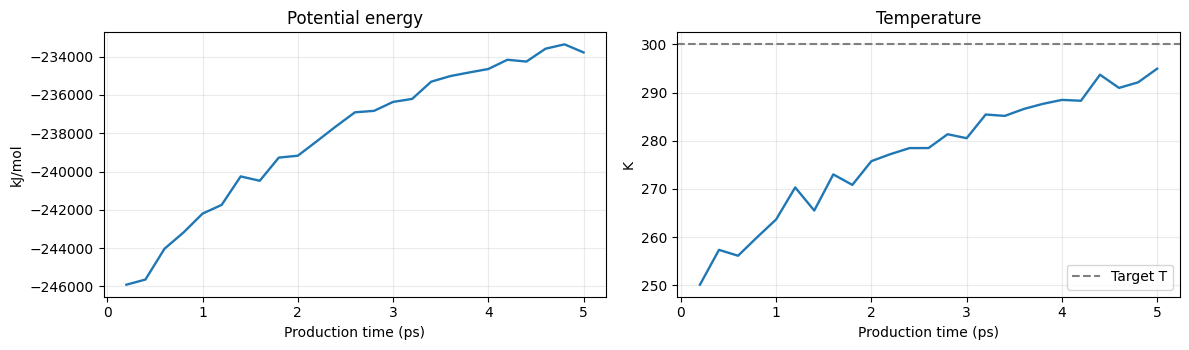

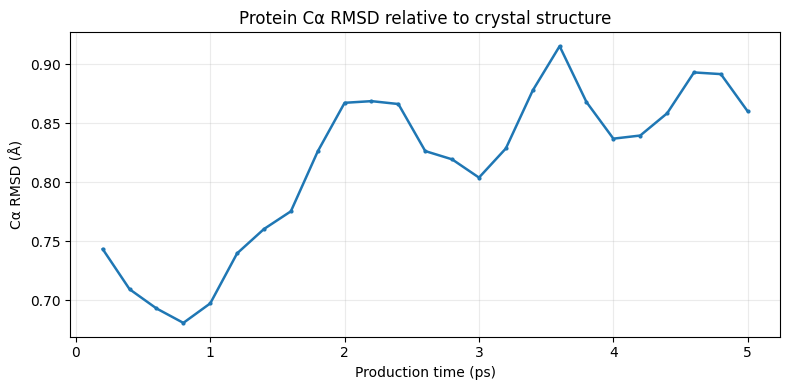

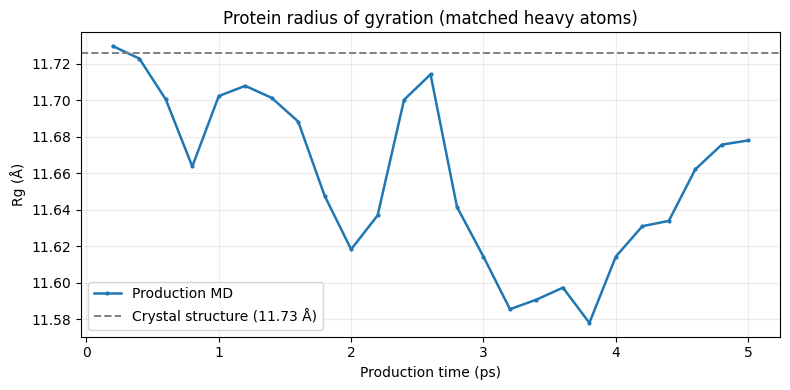

Crystal-referenced RMSD and crystal-baseline Rg saved.
Figures: energy_temperature.png, rmsd.png, rg.png
CSV: thermodynamic_data.csv, rmsd_rg_data.csv
Results: /content/drive/MyDrive/MD_HandsOn_Colab/1UBQ/verlet_andersen_5ps


In [13]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, mdtraj as mdtraj
import tempfile, shutil
from openmm.app import PDBFile
from openmm import unit

# Assemble completed production blocks: no NVT or NPT frames included.
completed=int((segment_dir/'progress.txt').read_text().strip())
if completed!=PRODUCTION_STEPS:
    raise RuntimeError('Run all production blocks before analyzing.')
blocks=[]
all_logs=[]
for start in range(0,PRODUCTION_STEPS,CHECKPOINT_INTERVAL):
    end=min(PRODUCTION_STEPS,start+CHECKPOINT_INTERVAL)
    dcd=segment_dir/f'block_{start:08d}_{end:08d}.dcd'
    csv=segment_dir/f'block_{start:08d}_{end:08d}.csv'
    if not dcd.exists() or not csv.exists(): raise FileNotFoundError(f'Missing segment {dcd} or {csv}')
    # Work on a short local path; Google Drive's mounted filesystem can be
    # unreliable for random-access binary DCD readers.
    with tempfile.TemporaryDirectory(prefix='md_segment_') as scratch:
        scratch = Path(scratch)
        shutil.copy2(dcd, scratch / 'block.dcd')
        shutil.copy2(solvated_path, scratch / 'topology.pdb')
        t = mdtraj.load_dcd(str(scratch / 'block.dcd'),
                            top=str(scratch / 'topology.pdb'))
    blocks.append(t)
    df=pd.read_csv(csv)
    df.columns=[str(c).strip().lstrip('#').strip().strip('"') for c in df.columns]
    all_logs.append(df)
traj=mdtraj.join(blocks,check_topology=True)
log=pd.concat(all_logs,ignore_index=True)
dt_ps=TIME_STEP_FS/1000.0
traj.time=(np.arange(traj.n_frames)+1)*REPORT_INTERVAL*dt_ps
log['production_time_ps']=(np.arange(len(log))+1)*REPORT_INTERVAL*dt_ps
if len(log)!=traj.n_frames: raise ValueError('Log/DCD frame counts disagree.')
with tempfile.TemporaryDirectory(prefix='md_merged_') as scratch:
    merged_local = Path(scratch) / 'production.dcd'
    traj.save_dcd(str(merged_local))
    shutil.copy2(merged_local, WORK_DIR / 'production.dcd')
print('Combined production DCD:',traj.n_frames,'frames,',traj.n_atoms,'atoms; last time:',traj.time[-1],'ps')

def find_column(df,text):
    return next((c for c in df.columns if text.lower() in c.lower()),None)
energy_col=find_column(log,'Potential Energy')
temp_col=find_column(log,'Temperature')
fig,axes=plt.subplots(1,2,figsize=(12,3.6))
for ax,col,title,ylabel in [(axes[0],energy_col,'Potential energy','kJ/mol'),
                             (axes[1],temp_col,'Temperature','K')]:
    if col is not None:
        ax.plot(log['production_time_ps'],pd.to_numeric(log[col]),lw=1.7)
    else:
        ax.text(.5,.5,f'{title} not in log',ha='center',va='center',transform=ax.transAxes)
    ax.set(title=title,xlabel='Production time (ps)',ylabel=ylabel)
    ax.grid(alpha=.25)
if temp_col is not None:
    axes[1].axhline(TEMPERATURE_K,ls='--',c='gray',label='Target T');axes[1].legend()
plt.tight_layout();fig.savefig(WORK_DIR/'energy_temperature.png',dpi=160);plt.show()

# ------------------------------------------------------------
# 3. Crystal structure: match atoms by chain, residue and atom
# ------------------------------------------------------------
# Read original downloaded PDB and the SOLVATED topology using OpenMM.
# MDTraj DCD atom indices correspond to the solvated PDB atom order.
crystal_pdb = PDBFile(str(WORK_DIR / f'{PDB_ID.upper().strip()}_original.pdb'))
solvated_pdb = PDBFile(str(WORK_DIR / 'system_solvated.pdb'))

def atom_key(atom):
    residue = atom.residue
    return (residue.chain.id, str(residue.id), residue.name, atom.name)

crystal_positions_nm = crystal_pdb.positions.value_in_unit(unit.nanometers)
crystal_atom_map = {
    atom_key(atom): np.asarray(crystal_positions_nm[atom.index], dtype=np.float64)
    for atom in crystal_pdb.topology.atoms()
}

# C-alpha coordinates missing from crystal cannot be compared.
ca_indices, crystal_ca_coords, ca_labels, ca_resseq = [], [], [], []
for atom in solvated_pdb.topology.atoms():
    if atom.name != 'CA' or atom.residue.name in ('HOH', 'NA', 'CL'):
        continue
    key = atom_key(atom)
    if key in crystal_atom_map:
        ca_indices.append(atom.index)
        crystal_ca_coords.append(crystal_atom_map[key])
        ca_labels.append(f'{atom.residue.chain.id}:{atom.residue.name}{atom.residue.id}')
        try:
            ca_resseq.append(int(atom.residue.id))
        except ValueError:
            ca_resseq.append(atom.residue.id)
if len(ca_indices) < 3:
    raise ValueError('Fewer than 3 matching C-alpha atoms between crystal and trajectory. '
                     'Verify PDB ID, selected chains, and residue numbering.')
if solvated_pdb.topology.getNumAtoms() != traj.n_atoms:
    raise ValueError('Solvated topology and DCD atom counts differ; do not analyze as matched systems.')

crystal_ca_coords = np.asarray(crystal_ca_coords, dtype=np.float32)
ca_traj = traj.atom_slice(np.asarray(ca_indices, dtype=int))
# Crystal CA reference: same atom order and topology as selected trajectory CA.
crystal_ca = mdtraj.Trajectory(crystal_ca_coords[np.newaxis, :, :], ca_traj.topology)
ca_traj.superpose(crystal_ca, frame=0)
rmsd_A = mdtraj.rmsd(ca_traj, crystal_ca, frame=0) * 10.0

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(traj.time, rmsd_A, marker='.', ms=4, lw=1.8)
ax.set(title='Protein Cα RMSD relative to crystal structure',
       xlabel='Production time (ps)', ylabel='Cα RMSD (Å)')
ax.grid(alpha=.25)
fig.tight_layout(); fig.savefig(WORK_DIR / 'rmsd.png', dpi=180, bbox_inches='tight'); plt.show()

# ------------------------------------------------------------
# 4. Rg: compare matched HEAVY protein atoms to crystal baseline
# ------------------------------------------------------------
# Crystal PDB typically lacks hydrogens. Use the same heavy atoms in both
# crystal and simulated structure so the mass-weighted Rg is comparable.
heavy_indices, crystal_heavy_coords = [], []
for atom in solvated_pdb.topology.atoms():
    if atom.element is None or atom.element.symbol == 'H':
        continue
    if atom.residue.name in ('HOH', 'NA', 'CL'):
        continue
    key = atom_key(atom)
    if key in crystal_atom_map:
        heavy_indices.append(atom.index)
        crystal_heavy_coords.append(crystal_atom_map[key])
if not heavy_indices:
    raise ValueError('No matching heavy protein atoms for crystal Rg comparison.')
heavy_traj = traj.atom_slice(np.asarray(heavy_indices, dtype=int))
crystal_heavy = mdtraj.Trajectory(
    np.asarray(crystal_heavy_coords, dtype=np.float32)[None, :, :],
    heavy_traj.topology)
rg_A = mdtraj.compute_rg(heavy_traj) * 10.0
rg_crystal_A = float(mdtraj.compute_rg(crystal_heavy)[0] * 10.0)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(traj.time, rg_A, marker='.', ms=4, lw=1.8, label='Production MD')
ax.axhline(rg_crystal_A, ls='--', lw=1.4, color='gray',
           label=f'Crystal structure ({rg_crystal_A:.2f} Å)')
ax.set(title='Protein radius of gyration (matched heavy atoms)',
       xlabel='Production time (ps)', ylabel='Rg (Å)')
ax.legend(); ax.grid(alpha=.25)
fig.tight_layout(); fig.savefig(WORK_DIR / 'rg.png', dpi=180, bbox_inches='tight'); plt.show()

# ------------------------------------------------------------
# 5. Save all numerical results locally
# ------------------------------------------------------------
log.to_csv(WORK_DIR / 'thermodynamic_data.csv', index=False)
pd.DataFrame({'production_time_ps': traj.time,
              'ca_rmsd_to_crystal_A': rmsd_A,
              'protein_rg_A': rg_A,
              'crystal_rg_A': rg_crystal_A}).to_csv(WORK_DIR / 'rmsd_rg_data.csv', index=False)
print('Crystal-referenced RMSD and crystal-baseline Rg saved.')
print('Figures: energy_temperature.png, rmsd.png, rg.png')
print('CSV: thermodynamic_data.csv, rmsd_rg_data.csv')
print('Results:', WORK_DIR.resolve())

## 12 · Animate the protein trajectory

View the protein without solvent. A maximum of 20 frames are included for responsiveness. The animation uses the already loaded coordinates and works after the DCD short-path workaround.

In [19]:
import py3Dmol
from IPython.display import display

protein_atoms = traj.topology.select('protein')
protein_view = traj.atom_slice(protein_atoms)
frame_ids = np.unique(np.linspace(0, protein_view.n_frames - 1,
                                  min(20, protein_view.n_frames), dtype=int))
models = []
# A single temporary PDB is reused for frame conversion; it is removed afterwards.
with tempfile.TemporaryDirectory(prefix='md_view_') as tmp:
    pdb_file = Path(tmp) / 'frame.pdb'
    for i in frame_ids:
        protein_view[int(i)].save_pdb(str(pdb_file))
        pdb_lines = pdb_file.read_text(encoding='utf-8').splitlines()
        # Remove END/MODEL lines to keep a valid multi-model PDB for 3Dmol.js.
        atoms = [s for s in pdb_lines if s.startswith(('ATOM  ', 'HETATM', 'TER   '))]
        models.append('MODEL\n' + '\n'.join(atoms) + '\nENDMDL\n')
view = py3Dmol.view(width=820, height=460)
view.addModelsAsFrames(''.join(models), 'pdb')
view.setStyle({'cartoon': {'color': 'spectrum'}})
view.zoomTo()
view.animate({'loop': 'forward', 'interval': 100})
display(view.show())


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

None

## 13 — Save your results as a ZIP (optional)

Files are already on Google Drive, including the production segments and XML restart states. This additional ZIP contains the main plots, numerical data, and merged production DCD for convenient submission. Large trajectories can make downloads slow.

In [20]:
import zipfile
submission_zip=WORK_DIR.parent/f'{PDB_ID.upper()}_{RUN_NAME}_results.zip'
files_to_include = [
    'production.dcd','system_solvated.pdb','energy_temperature.png',
    'rmsd.png','rg.png','thermodynamic_data.csv','rmsd_rg_data.csv',
    f'{PDB_ID.upper()}_original.pdb'
]
with zipfile.ZipFile(submission_zip,'w',zipfile.ZIP_DEFLATED) as z:
    for name in files_to_include:
        file=WORK_DIR/name
        if file.is_file():z.write(file,arcname=name)
print('Results ZIP:',submission_zip)
print('All saved output:',WORK_DIR)
# Optionally download:
# from google.colab import files
# files.download(str(submission_zip))

Results ZIP: /content/drive/MyDrive/MD_HandsOn_Colab/1UBQ/1UBQ_verlet_andersen_5ps_results.zip
All saved output: /content/drive/MyDrive/MD_HandsOn_Colab/1UBQ/verlet_andersen_5ps


## What students should submit

1. Screenshot of the cleaned protein and the solvated system.
2. `energy_temperature.png`, `rmsd.png`, and `rg.png`.
3. Describe why a separate NVT and NPT is perfomed?
4. Identify which stage has the barostat?
5. Report the final crystal-referenced Cα RMSD and compare the average Rg with the crystal baseline.

**Caution:** 5 ps is only a short demonstration and does not provide reliable sampling or convergence information.
